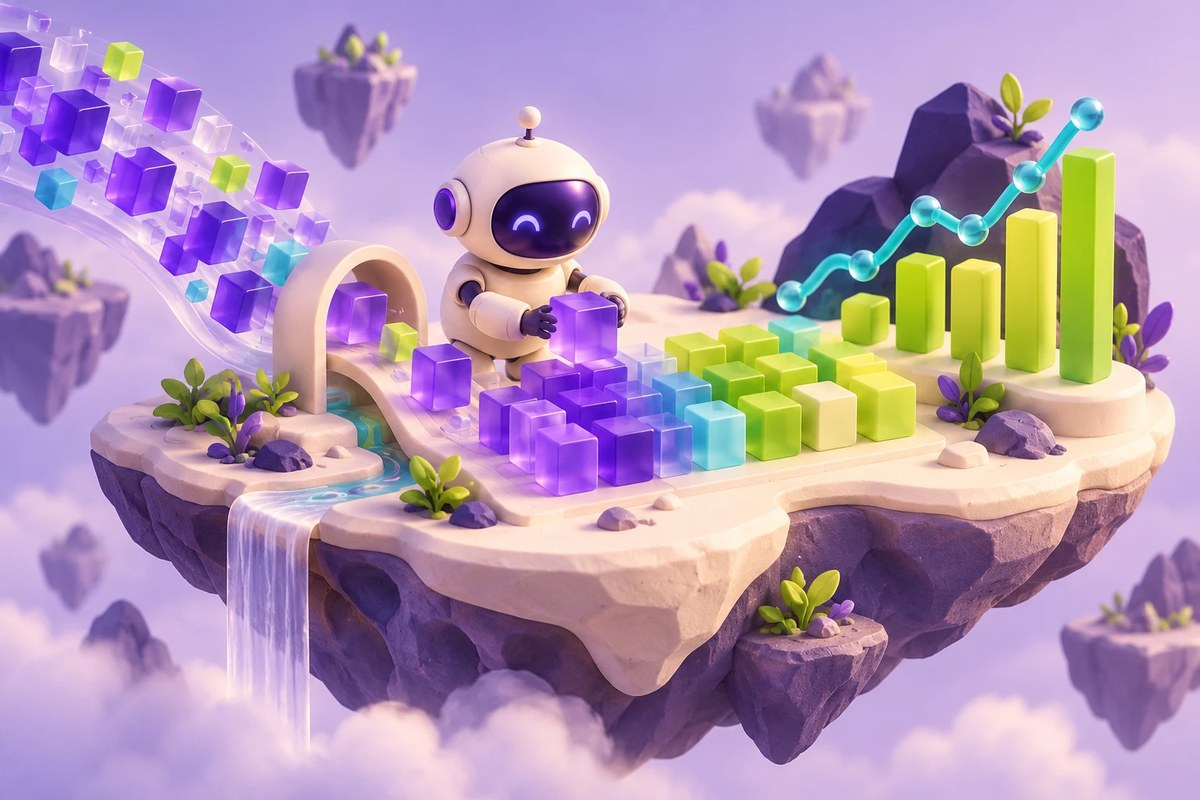

AI PATH · Python для машинного обучения · Урок 037

# NumPy: формы, маски и векторные операции

От CSV и сумм по осям до объединения массивов и точных срезов.

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-037-goal"></a>
## Что вы разберёте

Предсказывать форму результата и проверять границы отбора до выполнения операции.

### Перед началом

- Массивы NumPy и циклы
- Функции, условия и индексация

### Что понадобится

- NumPy и IPython для timeit
- Файлы train_vector_1.csv и iris.csv с ожидаемыми разделителями и заголовками
- Google Colab/Drive для исходного импорта и путей к данным

## Навигация по уроку

- [Цель и подготовка](#ai-037-goal)
- [Карта урока](#ai-037-map)
- [Загрузка вектора](#ai-037-section-01)
- [Цикл и измерение](#ai-037-section-02)
- [Оси массива](#ai-037-section-03)
- [Логические маски](#ai-037-section-04)
- [Структурированные записи](#ai-037-section-05)
- [Формы и объединение](#ai-037-section-06)
- [Классы значений](#ai-037-section-07)
- [Срез как контракт](#ai-037-section-08)
- [Проверьте понимание](#ai-037-practice)
- [Источники и ограничения](#ai-037-provenance)

<a id="ai-037-map"></a>
## Карта урока

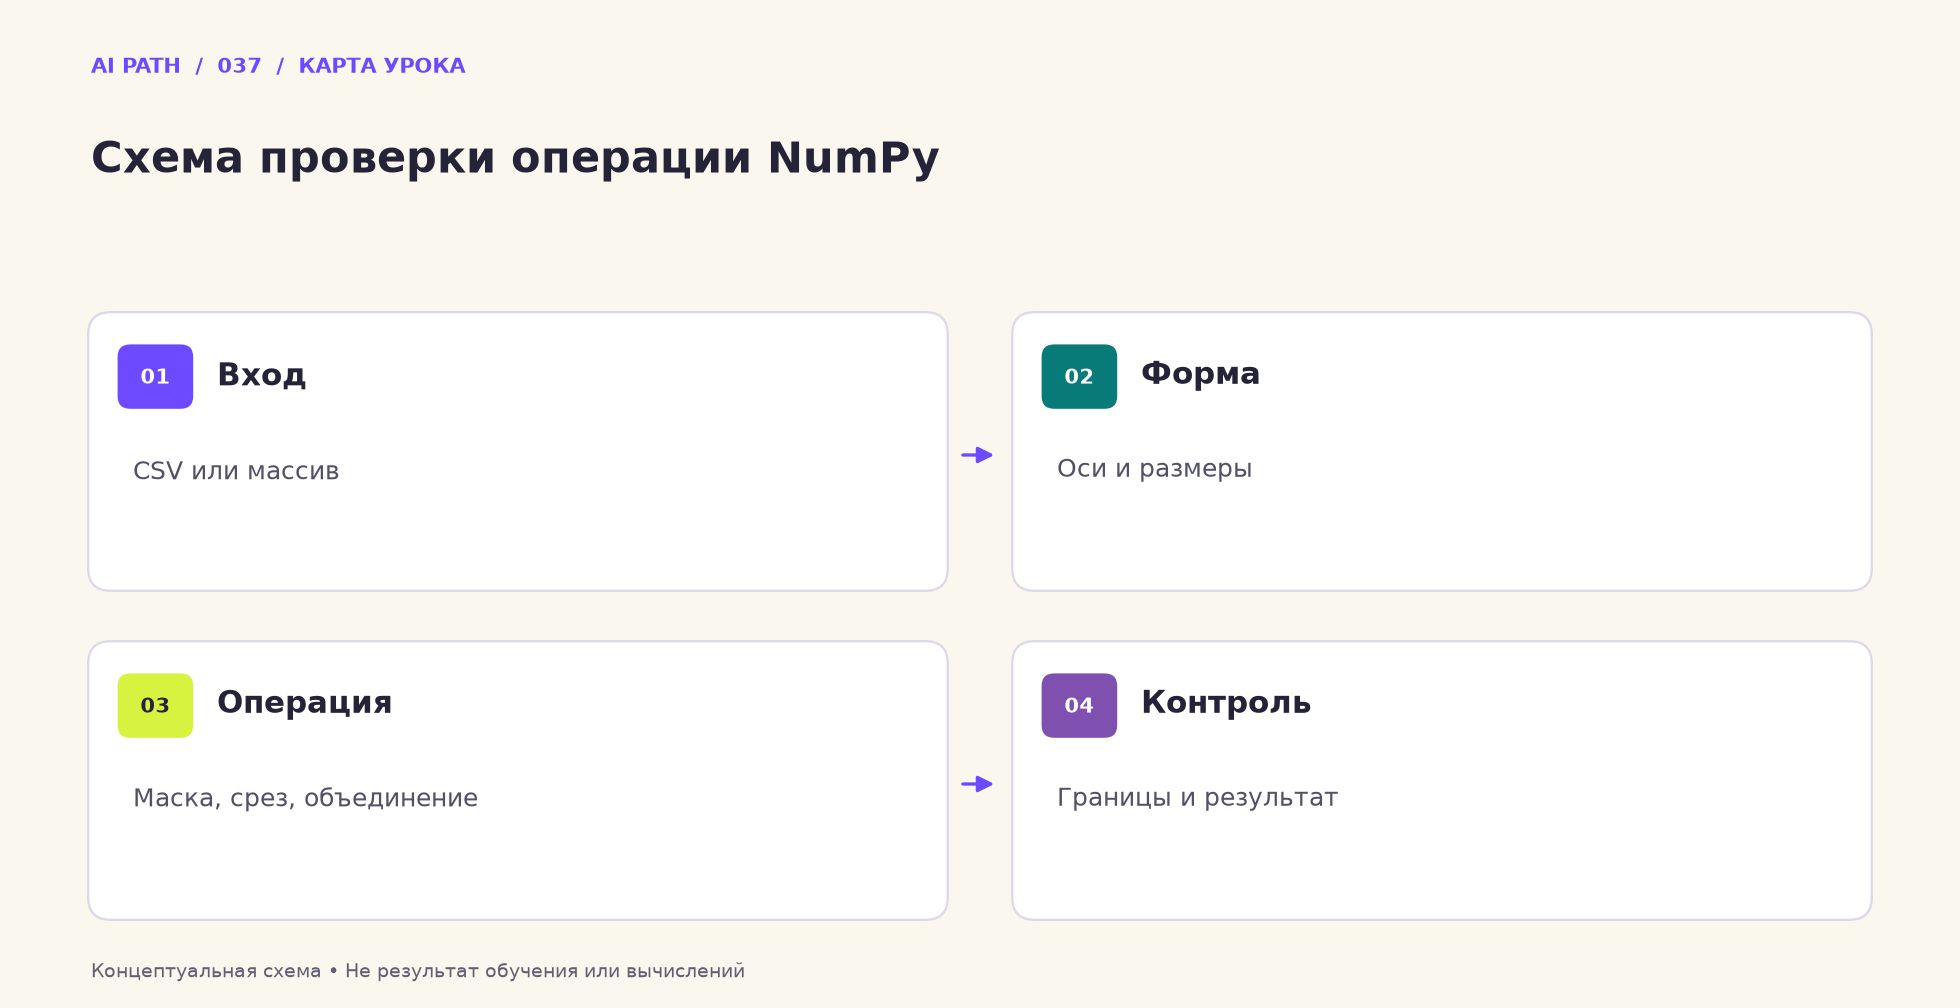

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Вход** — CSV или массив
2. **Форма** — Оси и размеры
3. **Операция** — Маска, срез, объединение
4. **Контроль** — Границы и результат

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%90%D0%BF%D1%80%D0%B5%D0%BB%D1%8C%D1%81%D0%BA%D0%B8%D0%B9_%D0%BA%D1%83%D1%80%D1%81_2020_Light_Python_%D0%94%D0%BE%D0%BC%D0%B0%D1%88%D0%BD%D0%B5%D0%B5_%D0%B7%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Нейронные сети

## Домашнее задание 2. Numpy и функции

# Light

<a id="ai-037-section-01"></a>
## 01 · Загрузка вектора

Проверьте размерность и тип после loadtxt, прежде чем вычислять среднее.

_Далее — исходные ячейки учебного материала._

### Задача 1

1. Подгрузите файл **train_vector_1.csv** с помощью функции **np.loadtxt**. 

2. Назовите подгруженный массив my_array.

3. Убедитесь, что подгруженный массив имеет тип np.ndarray (выведите тип переменной my_array).

Ссылка на файл: https://drive.google.com/open?id=1ngnrhmoMInequrA6JyAe90lEPhcbi0iH

In [ ]:
import numpy as np # Подключаем библиотеку numpy и задаем ей псевдоним np
from google.colab import drive


In [ ]:
# грузим массив из файла .csv
my_array = np.loadtxt('train_vector_1.csv',delimiter=',', skiprows=1) # skiprows=1 - пропускаем первую строку, поскольку в ней названия колонок базы 

In [ ]:
print(type(my_array)) 



<class 'numpy.ndarray'>


<a id="ai-037-section-02"></a>
## 02 · Цикл и измерение

Сравнивать скорость имеет смысл только для одинаковой операции и корректной команды timeit.

_Далее — исходные ячейки учебного материала._

### Задача 2

Напишите код, который считает среднее значение всех элементов массива (без использования встроенных функций np.mean и т.д.). Для решения задачи воспользуйтесь циклом.
* С помощью команды %%timeit отобразите время выполнения написанного кода.
* Преобразуйте массив my_array в список (с помощью метода list()), сохраните его в переменной my_list.
* В новой ячейке посчитайте среднее значение всех элементов списка (воспользуйтесь тем же самым кодом, что и для массива).
* Командой %%timeit отобразите время выполнения и этой ячейки.

In [ ]:

# среднее значение всех эллементов массива
 %%timeit -n 10
summa = 0
for idx, el in enumerate(my_array):
   summa +=el #  сумма всех элементов массива
v_mean = summa / (idx+1)   # среднее значение 
print(v_mean)



3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
10 loops, best of 3: 83.4 µs per loop


In [ ]:
my_list = list(my_array) # преобразование в список


In [ ]:
 %%timeit -n 10

summa = 0
for idx, el in enumerate(my_list):
   summa +=el #  сумма всех элементов массива
v_mean = summa / (idx+1)   # среднее значение 
print(v_mean)


3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
3.0543624161073835
10 loops, best of 3: 52.5 µs per loop


<a id="ai-037-section-03"></a>
## 03 · Оси массива

Сумма по axis=0 и по всему массиву отвечают на разные вопросы.

_Далее — исходные ячейки учебного материала._

### Задача 3

Подгрузите файл **iris.csv** с помощью встроенной функции **np.loadtxt**. Назовите его my_2d_array. Напиишите код, который считает сумму элементов массива по столбцам (для решения данной задачи воспользуйтесь разделом ноутбук "Операции с двумерными массивами и встроенные методы").

In [ ]:
 my_2d_array = np.loadtxt('iris.csv',delimiter=',',skiprows=1)

In [ ]:
 my_2d_array.sum(axis=0) #сумму элементов массива по столбцам

array([11175. ,   876.5,   458.6,   563.7,   179.9])

<a id="ai-037-section-04"></a>
## 04 · Логические маски

Проверьте диапазон случайных чисел и строгость условия меньше 20.

_Далее — исходные ячейки учебного материала._

### Задача 4 

* Используя библиотеку numpy, создайте массив 3x3, значения которого находятся в диапазоне от 11 до 40 (раздел "Семплирование из распределений"). 

* Не используя цикл for,  выведите на экран список элементов, которые меньше 20 (раздел "Индексация").

* Просуммируйте все элементы, не используя цикл for (раздел "Встроенные методы").


In [ ]:
my_array = np.random.randint(11,41,(3,3)) #от 11 до 40 // масссив 3 на 3
my_array # результат

array([[38, 19, 33],
       [38, 28, 37],
       [12, 38, 16]])

In [ ]:
my_array[my_array < 20] #список элементов меньше 20

array([19, 12, 16])

In [ ]:
my_array.sum() #сумма все элементов

259

<a id="ai-037-section-05"></a>
## 05 · Структурированные записи

Сортировка по возрасту отличается от сортировки обычного числового массива.

_Далее — исходные ячейки учебного материала._

### Задача 5

* Создайте массив, который будет содержать списки с именем студента(str), его возрастом(int) и средней оценкой(float) (обратите внимание на пример с занятия со списком автомобильных регионов).
* Отсортируйте такой массив (обратите внимание на параметр order метода sort()).
* Замените значение, отвечающее за возраст, у всех студентов на одно и то же, например, 10. Отсортируйте такой массив. 

In [ ]:
dtype1 = [('Имя','<U8'),('Возраст', np.int32),('Сред.оценка',np.float32)]
values =[('Иван',34,4.2),('Ден',15,2.2),('Лев',54,3.2),('Сеня',44,4.3)]
array_5 = np.array(values, dtype=dtype1)
print(array_5)

[('Иван', 34, 4.2) ('Ден', 15, 2.2) ('Лев', 54, 3.2) ('Сеня', 44, 4.3)]


In [ ]:
array_5.sort(order='Возраст')
array_5

array([('Ден', 15, 2.2), ('Иван', 34, 4.2), ('Сеня', 44, 4.3),
       ('Лев', 54, 3.2)],
      dtype=[('Имя', '<U8'), ('Возраст', '<i4'), ('Сред.оценка', '<f4')])

In [ ]:
array_5['Возраст'] = 10
array_5.sort(order='Возраст')
array_5

array([('Ден', 10, 2.2), ('Иван', 10, 4.2), ('Лев', 10, 3.2),
       ('Сеня', 10, 4.3)],
      dtype=[('Имя', '<U8'), ('Возраст', '<i4'), ('Сред.оценка', '<f4')])

## Pro версия

<a id="ai-037-section-06"></a>
## 06 · Формы и объединение

Проверьте размеры перед поэлементным умножением, concat, hstack и vsplit.

_Далее — исходные ячейки учебного материала._

### Задача 1

* Подгрузите массив **iris.csv** и назовите его my_array. 

* Создайте двумерный массив из случайных чисел той же размерности, что и my_array (раздел "Семплирование из распределений", потребуется использовать размерность массива my_array).

* Назовите его my_generated_array.

In [ ]:
import numpy as np

In [ ]:
#подгрузите массив iris.csv и назовите его my_array.
my_array = np.loadtxt('iris.csv',delimiter = ',', skiprows=1)

my_array.shape # узначем размерность который составляет (150, 5)

my_generated_array = np.random.random((150,5)) # Назовите его my_generated_array

print(my_array.shape)
print(my_generated_array.shape)


(150, 5)
(150, 5)


### Задача 2

* Выполните поэлементное умножение my_array на my_generated_array (раздел "векторные операции").

* Склейте массивы my_array, my_generated_array в один (могут помочь методы np.concatenate, np.vstack, np.hstack).

* Возьмите склеенный массив и разделите его на равные части (больше двух). Можно сделать вручную через циклы либо воспользоваться методом vsplit.

In [ ]:
# Выполните поэлементное умножение my_array на my_generated_array (раздел "векторные операции").
prod_array = my_array*my_generated_array
prod_array.shape

(150, 5)

In [ ]:
#Склейте массивы my_array, my_generated_array в один

# np.concatenate
a1_array = np.concatenate((my_array, my_generated_array))
print(a1_array.shape) # размерность полученного массива

# np.vstack
a2_array = np.vstack((my_array, my_generated_array))
print(a2_array.shape) # размерность полученного массива

# np.np.hstack
a3_array = np.hstack((my_array, my_generated_array))
print(a3_array.shape)


(300, 5)
(300, 5)
(150, 10)


In [ ]:
#Возьмите склеенный массив и разделите его на равные части (больше двух).
# Можно сделать вручную через циклы либо воспользоваться методом vsplit.

In [ ]:
list_array = np.vsplit(a1_array,4) # на 4 равные части
print(len(list_array)) # длина равна 4
print(list_array[0].shape) # размерность первого элемента

4
(75, 5)


### Задача 3

* Найдите все элементы массива my_array, которые больше трех и меньше 5 одновременно. Используйте методологию подвыборки массива с условием (раздел "Индексация").

In [ ]:
my_array[(my_array > 3) & (my_array <5)]

array([3.5, 4.9, 4.7, 3.2, 4.6, 3.1, 4. , 3.6, 3.9, 4.6, 3.4, 3.4, 4.4,
       4.9, 3.1, 3.7, 4.8, 3.4, 4.8, 4.3, 4. , 4.4, 3.9, 3.5, 3.8, 3.8,
       3.4, 3.7, 4.6, 3.6, 3.3, 4.8, 3.4, 3.4, 3.5, 3.4, 4.7, 3.2, 4.8,
       3.1, 3.4, 4.1, 4.2, 4.9, 3.1, 3.2, 3.5, 4.9, 3.6, 4.4, 3.4, 3.5,
       4.5, 4.4, 3.2, 3.5, 3.8, 4.8, 3.8, 4.6, 3.2, 3.7, 3.3, 3.2, 4.7,
       3.2, 4.5, 3.1, 4.9, 4. , 4.6, 4.5, 3.3, 4.7, 4.9, 3.3, 4.6, 3.9,
       3.5, 4.2, 4. , 4.7, 3.6, 3.1, 4.4, 4.5, 4.1, 4.5, 3.9, 3.2, 4.8,
       4. , 4.9, 4.7, 4.3, 4.4, 4.8, 4.5, 3.5, 3.8, 3.7, 3.9, 4.5, 3.4,
       4.5, 3.1, 4.7, 4.4, 4.1, 4. , 4.4, 4.6, 4. , 3.3, 4.2, 4.2, 4.2,
       4.3, 4.1, 3.3, 4.9, 4.5, 3.6, 3.2, 3.2, 3.8, 3.2, 4.9, 4.9, 3.3,
       3.2, 4.8, 4.9, 3.8, 3.4, 3.1, 4.8, 3.1, 3.1, 3.1, 3.2, 3.3, 3.4])

<a id="ai-037-section-07"></a>
## 07 · Классы значений

Границы 20 и 30 должны попадать ровно в одну категорию.

_Далее — исходные ячейки учебного материала._

### Задача 4

Создайте трехмерный массив размера 2 на 3 на 4, состоящий из случайных ВЕЩЕСТВЕННЫХ чисел от 15 до 37. Используйте встроенные методы библиотеки  np.random.

In [ ]:
s_array_3d = np.random.uniform(15,38,(2,3,4)) 
print(s_array_3d)

[[[20.16748518 29.11812462 17.55207794 24.84075111]
  [30.47792784 27.55350146 19.10635458 25.68457986]
  [22.79154063 34.05534602 19.9002084  37.20903502]]

 [[33.67971931 27.25959081 29.01860758 29.57095423]
  [19.6160723  36.27445783 31.70054271 25.3800442 ]
  [16.77392999 21.97838579 16.28027701 32.03735636]]]


### Задача 5

Используя массив из предыдущей задачи, преобразуйте его в новый массив со следующими значениями:

    * "small", если значения меньше 20
    * "medium", если значения в промежутке [20, 30]
    * "large", если значения больше 30

In [ ]:
n_array = np.full((2,3,4),'medium',dtype='<U32') # создадим массив размерности 2,3,4 з аполним словом 'medium'

#  "small", если значения меньше 20
n_array[s_array_3d < 20] = 'small'


# "medium", если значения в промежутке [20, 30] для наглядности напишу но можно не писать -- так как n_array = np.full((2,3,4),'medium',dtype='<U32') уже задал
n_array[(s_array_3d >= 20) & (s_array_3d <=30) ] = 'medium'


#"large", если значения больше 30
n_array[(s_array_3d > 30)] = 'large'
n_array

array([[['medium', 'medium', 'small', 'medium'],
        ['large', 'medium', 'small', 'medium'],
        ['medium', 'large', 'small', 'large']],

       [['large', 'medium', 'medium', 'medium'],
        ['small', 'large', 'large', 'medium'],
        ['small', 'medium', 'small', 'large']]], dtype='<U32')

<a id="ai-037-section-08"></a>
## 08 · Срез как контракт

Сопоставьте формулировку задания с полуоткрытым диапазоном индексов.

_Далее — исходные ячейки учебного материала._

### Задача 6

Создайте одномерный массив из случайных 10 значений. 

* Не используя цикл for, найдите сумму значений с 3 по 7 элемент.
* Найдите сумму квадратов последних двух элементов.

In [ ]:
#Создайте одномерный массив из случайных 10 значений.
array_10 = np.random.randint(0,9,10)
array_10

array([8, 0, 5, 4, 8, 3, 4, 2, 4, 4])

In [ ]:
#найдите сумму значений с 3 по 7 элемент.
array_10[1:5].sum()


17

In [ ]:
#Найдите сумму квадратов последних двух элементов.
(array_10[-2:] **2).sum()

32

<a id="ai-037-practice"></a>
## Проверьте понимание

1. Какая форма остаётся после sum(axis=0)?
2. Какие значения входят в medium и куда попадает ровно 30?
3. Почему срез [1:5] не выбирает элементы с третьего по седьмой?

### Один самостоятельный эксперимент

Создайте маленький массив с точными значениями 19, 20, 30 и 31 и проверьте все три категории.

**Критерий успеха:** Каждый элемент относится ровно к одной группе; границы объяснены словами и масками.

<a id="ai-037-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/Numpy/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%90%D0%BF%D1%80%D0%B5%D0%BB%D1%8C%D1%81%D0%BA%D0%B8%D0%B9_%D0%BA%D1%83%D1%80%D1%81_2020_Light_Python_%D0%94%D0%BE%D0%BC%D0%B0%D1%88%D0%BD%D0%B5%D0%B5_%D0%B7%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_2.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- CSV-файлы внешние; код ожидает определённую форму Iris, включая жёстко заданные 150 × 5.
- Положение %%timeit в исходных ячейках требует проверки в IPython; обычный Python его не исполняет.
- В uniform используется верхняя граница 38 вместо описанной 37; срез [1:5] не соответствует тексту задания.
- Случайность не фиксируется, делимость для vsplit не проверяется; новый запуск не выполнялся.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.